# EDA - Online Retail II

Notebook di esplorazione e pulizia del dataset **Online Retail II** (UCI Machine Learning Repository).

Obiettivo: caricare i due fogli del file Excel originale, esplorare la qualità dei dati, gestire i problemi tipici del dataset e produrre un CSV pulito in `data/processed`, pronto per essere caricato su SQL Server nello step successivo della pipeline.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

In [2]:
RAW_PATH = Path("../../data/raw/online_retail_II.xlsx")
PROCESSED_PATH = Path("../../data/processed")
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = PROCESSED_PATH / "online_retail_clean.csv"

## 1. Caricamento dati

Il file Excel contiene due fogli, uno per periodo:
- `Year 2009-2010`
- `Year 2010-2011`

Li carichiamo entrambi e li uniamo in un unico DataFrame.

In [3]:
sheets = ["Year 2009-2010", "Year 2010-2011"]
frames = [pd.read_excel(RAW_PATH, sheet_name=s) for s in sheets]
df = pd.concat(frames, ignore_index=True)

df = df.rename(columns={"Customer ID": "CustomerID"})

print(f"Righe totali dopo l'unione dei due fogli: {len(df):,}")
df.head()

Righe totali dopo l'unione dei due fogli: 1,067,371


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Panoramica generale

In [4]:
print("Dimensioni del dataset (righe, colonne):", df.shape)
print()
df.info()

Dimensioni del dataset (righe, colonne): (1067371, 8)



<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   CustomerID   824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


### Valori mancanti

In [5]:
missing = pd.DataFrame({
    "n_mancanti": df.isna().sum(),
    "perc_mancanti": (df.isna().mean() * 100).round(2),
})
missing.sort_values("n_mancanti", ascending=False)

,n_mancanti,perc_mancanti
CustomerID,243007,22.77
Description,4382,0.41
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


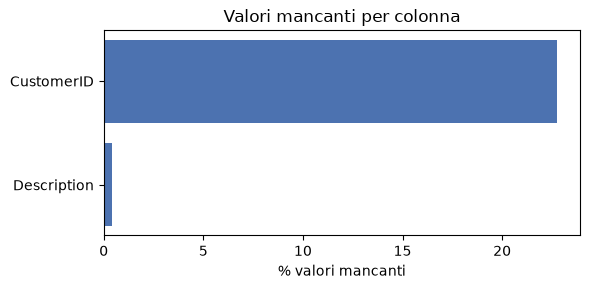

In [6]:
missing_to_plot = missing[missing["n_mancanti"] > 0]

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(missing_to_plot.index, missing_to_plot["perc_mancanti"], color="#4C72B0")
ax.set_xlabel("% valori mancanti")
ax.set_title("Valori mancanti per colonna")
plt.tight_layout()
plt.show()

### Statistiche descrittive

In [7]:
df.describe()

,Quantity,InvoiceDate,Price,CustomerID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [8]:
df.describe(include=["object", "str"])

,Invoice,StockCode,Description,Country
count,1067371,1067371,1062989,1067371
unique,53628,5305,5698,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1350,5829,5918,981330


## 3. Gestione dei problemi noti del dataset

Online Retail II presenta alcuni problemi ricorrenti, documentati anche nella letteratura che usa questo dataset. Li affrontiamo uno alla volta, con una motivazione esplicita per ogni decisione, così da mantenere tracciabile la pipeline di pulizia.

**Ordine delle operazioni**: rimuoviamo prima i duplicati esatti, poi le cancellazioni, poi le righe senza `CustomerID`, infine le righe con quantità o prezzo non positivi. L'ordine conta perché ogni filtro riduce il numero di righe su cui viene applicato il successivo.

### 3.1 Righe duplicate

I due fogli del file Excel non coprono periodi disgiunti: il foglio `2009-2010` arriva fino al 9 dicembre 2010, mentre il foglio `2010-2011` inizia il 1 dicembre 2010. Nella finestra di sovrapposizione (1-9 dicembre 2010) le **stesse fatture, con lo stesso numero e la stessa data**, compaiono in entrambi i fogli. Dopo l'unione dei due DataFrame queste righe sono duplicati esatti su tutte le colonne.

**Decisione**: rimuoviamo i duplicati esatti (`drop_duplicates`) per evitare di contare due volte le stesse transazioni, il che gonfierebbe artificialmente fatturato e quantità vendute nella prima settimana di dicembre 2010.

In [9]:
n_before = len(df)
n_duplicates = df.duplicated().sum()
print(f"Righe duplicate (tutte le colonne): {n_duplicates:,}")

df = df.drop_duplicates().reset_index(drop=True)
print(f"Righe rimosse: {n_before - len(df):,} -> Righe rimanenti: {len(df):,}")

Righe duplicate (tutte le colonne): 34,335


Righe rimosse: 34,335 -> Righe rimanenti: 1,033,036


### 3.2 Fatture di cancellazione (Invoice che inizia con "C")

Le fatture il cui codice inizia con la lettera `C` rappresentano **cancellazioni/resi**: sono transazioni con quantità negativa che annullano (in tutto o in parte) un ordine precedente.

**Decisione**: le rimuoviamo dal dataset pulito. Motivazione:
- Rappresentano l'annullamento di un acquisto, non un acquisto effettivo: includerle nelle analisi di comportamento d'acquisto (RFM, stagionalità) distorcerebbe le metriche basate su quantità e importi positivi.
- Tenerle insieme alle fatture originali senza un meccanismo di netting rischierebbe di far coesistere vendita e reso come due eventi scollegati invece che come un'unica transazione netta.

Il tasso di cancellazione (numero di fatture `C` sul totale) è comunque un indicatore utile a livello di business: lo riportiamo qui come nota, ma la sua analisi approfondita è fuori dallo scope di questo notebook di pulizia.

In [10]:
df["Invoice"] = df["Invoice"].astype(str)

is_cancellation = df["Invoice"].str.startswith("C")
cancel_rate = is_cancellation.mean() * 100
print(f"Fatture di cancellazione: {is_cancellation.sum():,} ({cancel_rate:.2f}% delle righe)")

n_before = len(df)
df = df[~is_cancellation].reset_index(drop=True)
print(f"Righe rimosse: {n_before - len(df):,} -> Righe rimanenti: {len(df):,}")

Fatture di cancellazione: 19,104 (1.85% delle righe)
Righe rimosse: 19,104 -> Righe rimanenti: 1,013,932


### 3.3 CustomerID mancante

Una quota consistente di righe non ha un `CustomerID` associato (acquisti non tracciati a livello di cliente, es. ordini telefonici o punti vendita non registrati).

**Decisione**: rimuoviamo queste righe. Motivazione: gli step successivi della pipeline (segmentazione RFM, analisi di abbandono) richiedono di attribuire ogni transazione a un cliente identificato. Senza `CustomerID` la riga non è utilizzabile per questi scopi, anche se rappresenta comunque fatturato reale. Se in futuro servisse un'analisi di fatturato aggregato indipendente dal cliente, andrebbe fatta su un dataset separato che includa anche queste righe.

In [11]:
n_before = len(df)
n_missing_customer = df["CustomerID"].isna().sum()
print(f"Righe senza CustomerID: {n_missing_customer:,} ({n_missing_customer / n_before * 100:.2f}%)")

df = df.dropna(subset=["CustomerID"]).reset_index(drop=True)
print(f"Righe rimosse: {n_before - len(df):,} -> Righe rimanenti: {len(df):,}")

Righe senza CustomerID: 234,437 (23.12%)
Righe rimosse: 234,437 -> Righe rimanenti: 779,495


### 3.4 Quantità o prezzo non positivi

Anche dopo aver rimosso le cancellazioni, restano alcune righe con `Quantity <= 0` o `Price <= 0`: si tratta tipicamente di rettifiche contabili, articoli omaggio/promozionali a prezzo zero o errori di inserimento (es. codici come `ADJUST BAD DEBT`, `Manual`).

**Decisione**: le rimuoviamo. Motivazione: non rappresentano transazioni di vendita valide e un prezzo o una quantità non positivi renderebbero incoerenti le metriche calcolate a valle (es. `TotalPrice`, valore monetario nella RFM).

In [12]:
n_before = len(df)
invalid_qty = (df["Quantity"] <= 0).sum()
invalid_price = (df["Price"] <= 0).sum()
print(f"Righe con Quantity <= 0: {invalid_qty:,}")
print(f"Righe con Price <= 0: {invalid_price:,}")

df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].reset_index(drop=True)
print(f"Righe rimosse: {n_before - len(df):,} -> Righe rimanenti: {len(df):,}")

Righe con Quantity <= 0: 0
Righe con Price <= 0: 70


Righe rimosse: 70 -> Righe rimanenti: 779,425


### 3.5 Transazioni con quantita' implausibili (errori di inserimento dati)

Un'analisi successiva della distribuzione di `Quantity` (vedi soglie 1.000 / 5.000 / 10.000) ha fatto emergere due righe estreme e isolate:

| Invoice | StockCode | Descrizione | CustomerID | Quantity |
|---|---|---|---|---|
| 581483 | 23843 | PAPER CRAFT , LITTLE BIRDIE | 16446 | 80.995 |
| 541431 | 23166 | MEDIUM CERAMIC TOP STORAGE JAR | 12346 | 74.215 |

Entrambe sono l'**unica riga della propria fattura** (un solo articolo, un solo cliente, un solo ordine) e riguardano articoli da regalo/decorazione di uso domestico, non materiale da rivendita all'ingrosso dichiarato. Comprare oltre 74.000 pezzi di un singolo articolo decorativo in un ordine isolato, mai ripetuto, non e' un pattern di acquisto plausibile: e' molto piu' coerente con un errore di inserimento (es. quantita' digitata per errore, campo confuso con un altro codice numerico) che con una transazione reale.

Il confronto con un caso simile ma legittimo chiarisce la differenza: il **CustomerID 13902** ha diverse righe con `Quantity` tra 12.000 e 19.000 (piatti e tazze di carta a ~0,10£/unita', fatture multiple nel tempo) - un profilo coerente con un rivenditore all'ingrosso genuino, **non** viene toccato da questo filtro.

**Decisione**: escludiamo queste due righe specifiche, identificate per Invoice+StockCode+CustomerID+Quantity, non con un taglio generico per soglia di quantita' (che colpirebbe anche clienti come il 13902).

In [13]:
transazioni_da_escludere = [
    {"Invoice": "581483", "StockCode": "23843", "CustomerID": 16446, "Quantity": 80995},
    {"Invoice": "541431", "StockCode": "23166", "CustomerID": 12346, "Quantity": 74215},
]

# StockCode e' una colonna "object" con tipi misti (int per i codici puramente
# numerici, str per quelli alfanumerici come "85123A"): confrontiamo castando a
# stringa, altrimenti il confronto con un letterale stringa fallisce silenziosamente.
stock_code_str = df["StockCode"].astype(str)

n_before = len(df)
for t in transazioni_da_escludere:
    mask = (
        (df["Invoice"] == t["Invoice"])
        & (stock_code_str == t["StockCode"])
        & (df["CustomerID"] == t["CustomerID"])
        & (df["Quantity"] == t["Quantity"])
    )
    n_match = mask.sum()
    assert n_match == 1, f"Attesa esattamente 1 riga per {t}, trovate {n_match}"
    print(f"Invoice {t['Invoice']} / StockCode {t['StockCode']}: {n_match} riga trovata e rimossa")
    df = df[~mask]
    stock_code_str = stock_code_str[~mask]

print(f"Righe rimosse: {n_before - len(df):,} -> Righe rimanenti: {len(df):,}")

Invoice 581483 / StockCode 23843: 1 riga trovata e rimossa


Invoice 541431 / StockCode 23166: 1 riga trovata e rimossa
Righe rimosse: 2 -> Righe rimanenti: 779,423


## 4. Preparazione tipi e colonne derivate

- `CustomerID`: convertito da `float` a `int`, ora che non ci sono più valori mancanti.
- `InvoiceDate`: già in formato datetime.
- `TotalPrice`: colonna derivata (`Quantity * Price`), utile fin da questo step per la segmentazione RFM successiva.

In [14]:
df["CustomerID"] = df["CustomerID"].astype("int64")
df["TotalPrice"] = df["Quantity"] * df["Price"]

df.dtypes

Invoice                   str
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
CustomerID              int64
Country                   str
TotalPrice            float64
dtype: object

## 5. Validazione finale

In [15]:
print("Dimensioni finali:", df.shape)
print()
print("Valori mancanti residui:")
print(df.isna().sum())

Dimensioni finali: (779423, 9)

Valori mancanti residui:


Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64


In [16]:
df.describe()

,Quantity,InvoiceDate,Price,CustomerID,TotalPrice
count,779423.000000,779423,779423.000000,779423.000000,779423.000000
mean,13.290270,2011-01-03 01:44:03.168420,3.218492,15320.362833,21.976707
min,1.000000,2009-12-01 07:45:00,0.001000,12346.000000,0.001000
25%,2.000000,2010-07-02 14:39:00,1.250000,13971.000000,4.950000
50%,6.000000,2010-12-02 14:09:00,1.950000,15247.000000,12.480000
75%,12.000000,2011-08-01 13:44:00,3.750000,16794.000000,19.800000
max,19152.000000,2011-12-09 12:50:00,10953.500000,18287.000000,38970.000000
std,76.131234,NaN,29.676178,1695.691125,87.634176


In [17]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


## 6. Salvataggio del dataset pulito

Salviamo il DataFrame pulito in `data/processed/online_retail_clean.csv`, pronto per il caricamento su SQL Server.

Note per lo step successivo:
- `Invoice`: testo (dopo la rimozione delle cancellazioni contiene solo codici numerici, ma resta comunque un identificativo, non un valore su cui fare aritmetica -> tipo testo/varchar in SQL Server).
- `CustomerID`: intero.
- `InvoiceDate`: datetime.
- `Price` e `TotalPrice`: numerici decimali (attenzione alla precisione in fase di import, es. `DECIMAL(10,2)`).
- `Description`, `StockCode`, `Country`: testo.

In [18]:
df.to_csv(OUTPUT_FILE, index=False, encoding="utf-8")
print(f"Dataset pulito salvato in: {OUTPUT_FILE.relative_to('../..').as_posix()}")
print(f"Dimensioni file: {OUTPUT_FILE.stat().st_size / 1_000_000:.1f} MB")

Dataset pulito salvato in: data/processed/online_retail_clean.csv
Dimensioni file: 75.7 MB
